# Sampling demo

Generate 256 × 256 images from text prompts with JiT-T2I trained with Pixel+LILIE.
The generator checkpoint ([Hugging Face](https://huggingface.co/suchiragarwal/lilie)) and the Qwen3
text encoder are downloaded on first use. Install `requirements.txt` and run on a GPU or TPU.

In [1]:
import sys
sys.path.insert(0, "..")

import jax
import jax.numpy as jnp
import numpy as np
from flax import nnx
from huggingface_hub import snapshot_download
from PIL import Image

from common import checkpoint
from jit import diffusion
from jit.config import JiTConfig
from train_jit import TextEncoder, build_denoiser

## Load the model

Choose `"g"` (1.1B parameters) or `"xl"` (700M parameters).

In [2]:
model_size = "g"
folder = f"jit-t2i/{model_size}_pixel+lilie-390600"
path = snapshot_download("suchiragarwal/lilie", allow_patterns=[f"{folder}/meta.json", f"{folder}/ema_weights.safetensors"])
path = f"{path}/{folder}"

cfg = JiTConfig(**checkpoint.load_meta(path)["config"])
graphdef, params, rest = nnx.split(build_denoiser(cfg, compute_dtype=jnp.float32, remat=False), nnx.Param, ...)
model = nnx.merge(graphdef, jax.device_put(checkpoint.load(path, "ema_weights", params)), rest)
text_encoder = TextEncoder(cfg.text_encoder, cfg.max_length, jax.sharding.Mesh(jax.devices()[:1], ("data",)))

## Sample

Play around with the prompts!

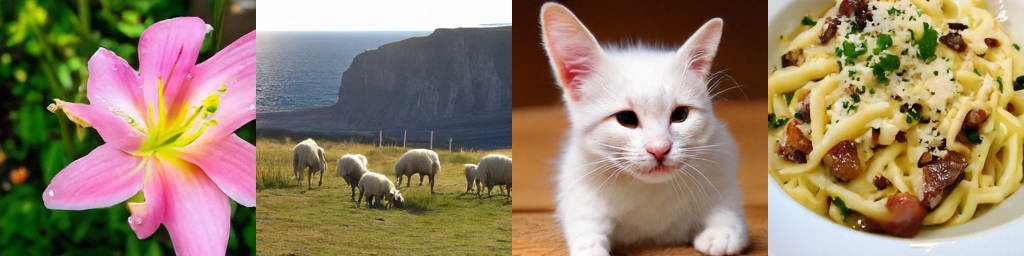

In [3]:
prompts = [
    "A pink lily flower with a yellow center blooms in a garden. There are drops of water on the petals.",
    "Several sheep with white wool graze in a grassy field near a fence. Behind them, tall cliffs rise beside the ocean under a bright sky.",
    "A small white kitten sits on a wooden surface, looking directly at the camera. Its ears are perked up, and its paws are resting in front of it. The setting appears to be indoors, with wood grain visible beneath the kitten.",
    "A bowl of creamy pasta with mushrooms, bacon bits, and green onions sits on a white plate. The dish is topped with grated cheese and garnished with chopped herbs.",
]
guidance = 4.85
num_steps = 50
seed = 0

noise = jax.random.normal(jax.random.key(seed), (len(prompts), 3, cfg.input_size, cfg.input_size))
samples = diffusion.euler_sample(model, noise, text_encoder(prompts), text_encoder.null_condition,
                                 num_steps=num_steps, guidance=guidance, timeshift=cfg.timeshift, t_eps=cfg.t_eps)
images = np.clip((np.asarray(samples) + 1) * 127.5 + 0.5, 0, 255).astype(np.uint8).transpose(0, 2, 3, 1)
Image.fromarray(np.hstack(images))